In [8]:
import random
from collections import Counter

import chess
import torch
import torch.nn as nn
import torch.nn.functional as F

In [9]:
def randomMove(board):
    legalMoves=list(board.legal_moves)
    return random.choice(legalMoves)

In [10]:
def playGame(whitePlayer, blackPlayer):
    board=chess.Board()
    while not board.is_game_over():
        player=whitePlayer if board.turn==chess.WHITE else blackPlayer
        board.push(player(board))
    return board.result()

In [11]:
results=[]
for gameNumber in range(20):
    result=playGame(randomMove, randomMove)
    results.append(result)

print(results)
print("White wins:", results.count("1-0"))
print("Black wins:", results.count("0-1"))
print("Draws:", results.count("1/2-1/2"))

['1/2-1/2', '1/2-1/2', '1-0', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '0-1', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2']
White wins: 1
Black wins: 1
Draws: 18


In [12]:
def boardToTensor(board):
    tensor=torch.zeros(13,8,8)
    for square,piece in board.piece_map().items():
        planeIndex=piece.piece_type-1
        if piece.color==chess.BLACK:
            planeIndex+=6
        row=square//8
        col=square%8
        tensor[planeIndex,row,col]=1
    if board.turn==chess.WHITE:
        tensor[12,:,:]=1
    return tensor

In [13]:
t=boardToTensor(chess.Board())
print(t.shape)
print(t.sum().item())
print(t[0].sum().item())

torch.Size([13, 8, 8])
96.0
8.0


In [14]:
class ChessNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(13, 64, kernel_size=3, padding=1)
        self.conv2=nn.Conv2d(64,64,kernel_size=3,padding=1)
        self.conv3=nn.Conv2d(64,64,kernel_size=3,padding=1)
        self.policyHead=nn.Linear(64*8*8,4096)
        self.valueHead=nn.Linear(64*8*8,1)

    def forward(self, x):
        x=F.relu(self.conv1(x))
        x=F.relu(self.conv2(x))
        x=F.relu(self.conv3(x))
        x=x.view(x.size(0), -1)
        policy=self.policyHead(x)
        value=torch.tanh(self.valueHead(x))
        return policy,value

In [15]:
net=ChessNet()
x=boardToTensor(chess.Board()).unsqueeze(0)
with torch.no_grad():
    policy,value=net(x)

print(x.shape)
print(policy.shape)
print(value.shape)
print(value.item())
print(sum(p.numel() for p in net.parameters()))


torch.Size([1, 13, 8, 8])
torch.Size([1, 4096])
torch.Size([1, 1])
0.0077391150407493114
16866817


In [47]:
numMoves=4096
def moveToIndex(move):
    return move.from_square*64+move.to_square

def indexToMove(index,board):
    fromSquare=index//64
    toSquare=index%64
    piece=board.piece_at(fromSquare)
    promotion=None
    if piece is not None and piece.piece_type == chess.PAWN and chess.square_rank(toSquare) in (0,7):
        promotion=chess.QUEEN
    return chess.Move(fromSquare,toSquare,promotion=promotion)

In [17]:
def legalMovesToMask(board):
    mask=torch.zeros(4096,dtype=torch.bool)
    for move in board.legal_moves:
        mask[moveToIndex(move)]=True
    return mask

def maskedPolicy(policyLogits, board):
    mask = legalMovesToMask(board)
    logits = policyLogits.clone()
    logits[~mask] = float('-inf')
    probs = torch.softmax(logits, dim=0)
    return probs, mask

In [18]:
board=chess.Board()
print(moveToIndex(chess.Move.from_uci("e2e4")))
print(legalMovesToMask(board).sum().item())
print(all(indexToMove(moveToIndex(m), board) == m for m in board.legal_moves))

with torch.no_grad():
    policy,value=net(boardToTensor(board).unsqueeze(0))
probs,mask=maskedPolicy(policy[0],board)
print(probs.sum().item())
print((probs > 0).sum().item())

796
20
True
1.0
20


In [19]:
def netPlayer(board):
    with torch.no_grad():
        policy,value=net(boardToTensor(board).unsqueeze(0))
    probs,mask=maskedPolicy(policy[0], board)
    index=torch.multinomial(probs, 1).item()
    return indexToMove(index, board)

In [20]:
results = [playGame(netPlayer,randomMove) for _ in range(10)]
print(results)

['1/2-1/2', '0-1', '1/2-1/2', '1-0', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2', '1/2-1/2']


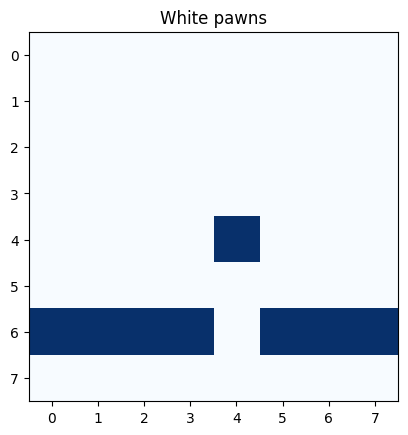

In [21]:
import matplotlib.pyplot as plt

board = chess.Board()
for move in ["e4", "e5", "Nf3", "Nc6", "Bb5"]:
    board.push_san(move)

planes = boardToTensor(board)

plt.imshow(planes[0].flip(0).numpy(), cmap="Blues")
plt.title("White pawns")
plt.show()

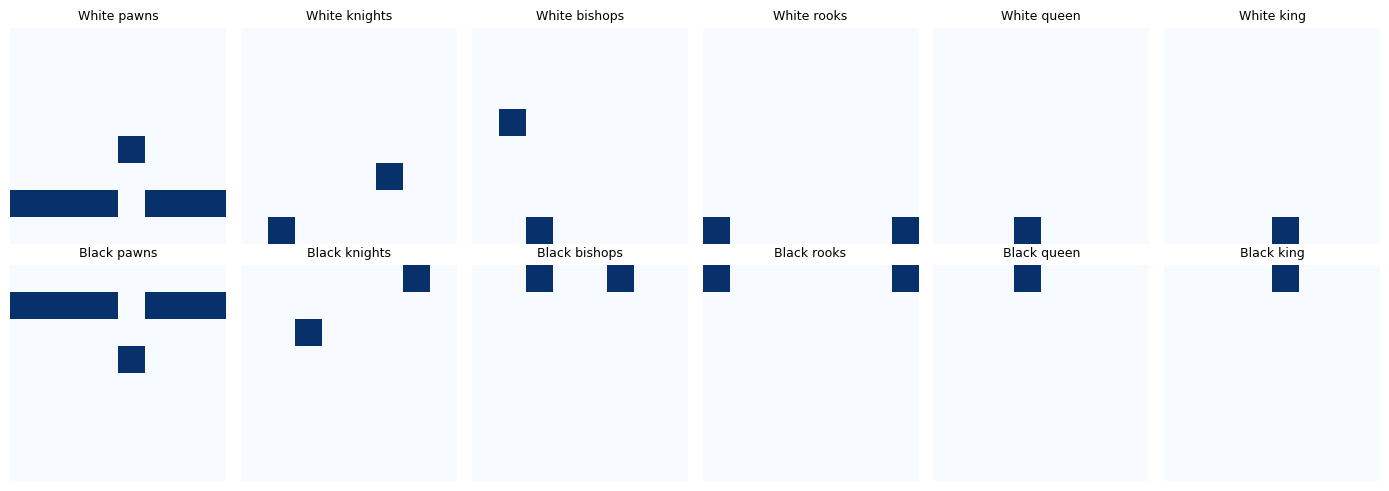

In [22]:
names = ["White pawns", "White knights", "White bishops", "White rooks", "White queen", "White king",
         "Black pawns", "Black knights", "Black bishops", "Black rooks", "Black queen", "Black king"]

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(planes[i].flip(0).numpy(), cmap="Blues")
    ax.set_title(names[i], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("../docs/board_planes.png", dpi=200)
plt.show()

In [23]:
class Node:
    def __init__(self,prior):
        self.prior=prior
        self.visitCount=0
        self.valueSum=0.0
        self.children={}

    def value(self):
        if self.visitCount==0:
            return 0.0
        return self.valueSum/self.visitCount

    def isExpanded(self):
        return len(self.children) >0

In [24]:
root=Node(prior=1.0)
print(root.value(),root.isExpanded())

root.visitCount=4
root.valueSum=2.0
print(root.value())

0.0 False
0.5


In [ ]:
def expandNode(node, board, net):
    with torch.no_grad():
        policy,value=net(boardToTensor(board).unsqueeze(0))
    probs,mask=maskedPolicy(policy[0],board)
    for move in board.legal_moves:
        index=moveToIndex(move)
        node.children[index]=Node(prior=probs[index].item())
    return value.item()

In [37]:
board=chess.Board()
root=Node(prior=1.0)
v=expandNode(root,board,net)

print(len(root.children))
print(round(sum(child.prior for child in root.children.values()), 4))
print(round(max(child.prior for child in root.children.values()), 4))
print(v)
print(root.isExpanded())

20
1.0
0.0515
0.0077391150407493114
True


In [38]:
import math

def selectChild(node, cPuct=1.5):
    bestScore= -float('inf')
    bestIndex=None
    bestChild=None
    for index,child in node.children.items():
        explorationBonus=cPuct * child.prior * math.sqrt(max(1, node.visitCount)) / (1 + child.visitCount)
        score= -child.value()+explorationBonus
        if score>bestScore:
            bestScore=score
            bestIndex=index
            bestChild=child
    return bestIndex,bestChild

In [39]:
parent=Node(prior=1.0)
parent.visitCount=10
parent.children[0]=Node(prior=0.6)
parent.children[1]=Node(prior=0.3)
parent.children[2]=Node(prior=0.1)

print(selectChild(parent)[0])

parent.children[0].visitCount=5
parent.children[0].valueSum=4.0
print(selectChild(parent)[0])

parent.children[0].visitCount=2
parent.children[0].valueSum=-1.8
print(selectChild(parent)[0])

0
1
0


In [40]:
def simulate(root,board,net,cPuct=1.5):
    board=board.copy()
    node=root
    path=[node]

    while node.isExpanded():
        index,node=selectChild(node, cPuct)
        board.push(indexToMove(index, board))
        path.append(node)

    if board.is_game_over():
        value= -1.0 if board.is_checkmate() else 0.0
    else:
        value=expandNode(node, board, net)

    for n in reversed(path):
        n.visitCount+=1
        n.valueSum+=value
        value= -value

In [41]:
board=chess.Board()
root=Node(prior=1.0)
for _ in range(50):
    simulate(root, board,net)

print(root.visitCount)
print(len(root.children))
print(sum(child.visitCount for child in root.children.values()))
print(board.fen() == chess.STARTING_FEN)

50
20
49
True


In [44]:
mateBoard = chess.Board("6k1/5ppp/8/8/8/8/5PPP/R5K1 w - - 0 1")
root = Node(prior=1.0)
for _ in range(200):
    simulate(root, mateBoard, net)

bestIndex = max(root.children, key=lambda i: root.children[i].visitCount)
print(indexToMove(bestIndex, mateBoard))
print(root.children[bestIndex].visitCount)

a1a8
180


In [ ]:
def search(board,net,numSimulations=100,cPuct=1.5):
    root=Node(prior=1.0)
    for _ in range(numSimulations):
        simulate(root,board,net,cPuct)

    visitCounts=torch.zeros(numMoves)
    for index, child in root.children.items():
        visitCounts[index]=child.visitCount

    return visitCounts/visitCounts.sum(),root

In [ ]:
board=chess.Board()
visitProbs,root=search(board,net,numSimulations=100)
print(visitProbs.shape)
print(round(visitProbs.sum().item(),4))
print((visitProbs>0).sum().item())

top=torch.topk(visitProbs,3)
for p,index in zip(top.values,top.indices):
    print(indexToMove(index.item(),board),round(p.item(),3))

torch.Size([4096])
1.0
20
g1h3 0.051
g1f3 0.051
b1a3 0.051


In [ ]:
mateBoard=chess.Board("6k1/5ppp/8/8/8/8/5PPP/R5K1 w - - 0 1")
visitProbs,root=search(mateBoard,net,numSimulations=100)
print(indexToMove(torch.argmax(visitProbs).item(), mateBoard), round(visitProbs.max().item(), 2))

a1a8 0.87


In [51]:
def makeMCTSPlayer(net,numSimulations=50):
    def player(board):
        visitProbs,root=search(board,net,numSimulations)
        index=torch.argmax(visitProbs).item()
        return indexToMove(index,board)
    return player

In [52]:
import time

start=time.time()
search(chess.Board(),net,numSimulations=50)
print(round(time.time()-start,2), "seconds")

0.47 seconds


In [53]:
mcts=makeMCTSPlayer(net,numSimulations=50)

for i in range(2):
    print("MCTS as white:",playGame(mcts,randomMove))
    print("MCTS as black:",playGame(randomMove,mcts))

MCTS as white: 1/2-1/2
MCTS as black: 1/2-1/2
MCTS as white: 1-0
MCTS as black: 0-1


In [54]:
import os

os.makedirs("../checkpoints",exist_ok=True)
path="../checkpoints/gen_000.pt"
if not os.path.exists(path):
    torch.save(net.state_dict(),path)